# Day 16 — Forecasting Baseline

## Objective

The objective of Day 16 is to establish baseline models for forecasting future water-quality parameter values.

Two forecasting approaches will be evaluated:

1. Persistence baseline
2. Random Forest regression model

The models will be evaluated using a chronological holdout approach with MAE and RMSE.

Predicted values will also be compared with actual values using time-series plots.

## Forecasting Target

The forecasting task will predict the next value of a selected water-quality parameter using historical observations.

## Evaluation Strategy

The data will be evaluated chronologically to preserve the time-series structure and avoid future-data leakage.

The primary evaluation metrics are:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

Lower MAE and RMSE indicate smaller prediction errors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error

base_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\data\processed"

train_df = pd.read_csv(base_path + r"\train_v1_engineered.csv")
val_df = pd.read_csv(base_path + r"\validation_v1_engineered.csv")
test_df = pd.read_csv(base_path + r"\test_v1_engineered.csv")

for data in [train_df, val_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )
    data.sort_values("timestamp", inplace=True)
    data.reset_index(drop=True, inplace=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (2291, 42)
Validation: (491, 42)
Test: (491, 42)


In [2]:
# Forecasting target
target_col = "ph"

print("Forecasting target:", target_col)

print("\nTarget statistics:")
print(train_df[target_col].describe())

Forecasting target: ph

Target statistics:
count    2.291000e+03
mean    -6.009064e-16
std      1.000218e+00
min     -4.527515e+00
25%     -6.225664e-01
50%     -3.622581e-02
75%      6.130631e-01
max      4.553513e+00
Name: ph, dtype: float64


In [3]:
# Persistence baseline
# Predict the next pH value using the current pH value

def create_persistence_data(data, target_col):
    df = data[["timestamp", target_col]].copy()
    
    df["actual"] = df[target_col].shift(-1)
    df["predicted"] = df[target_col]
    
    # Remove the final row because it has no next actual value
    df = df.dropna(subset=["actual"]).reset_index(drop=True)
    
    return df


train_persistence = create_persistence_data(train_df, target_col)
val_persistence = create_persistence_data(val_df, target_col)
test_persistence = create_persistence_data(test_df, target_col)

# Evaluate on chronological test holdout
persistence_mae = mean_absolute_error(
    test_persistence["actual"],
    test_persistence["predicted"]
)

persistence_rmse = np.sqrt(
    mean_squared_error(
        test_persistence["actual"],
        test_persistence["predicted"]
    )
)

print("Persistence Baseline Results")
print("----------------------------")
print("MAE :", round(persistence_mae, 4))
print("RMSE:", round(persistence_rmse, 4))

Persistence Baseline Results
----------------------------
MAE : 1.1335
RMSE: 1.6095


In [4]:
# Create next-step forecasting target

for data in [train_df, val_df, test_df]:
    data["ph_next"] = data["ph"].shift(-1)

# Remove the final row because it has no next-step target
train_model = train_df.dropna(subset=["ph_next"]).copy()
val_model = val_df.dropna(subset=["ph_next"]).copy()
test_model = test_df.dropna(subset=["ph_next"]).copy()

# Features available for prediction
forecast_features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity",
    "hour",
    "day_of_week",
    "day",
    "month",
    "ph_lag_1",
    "ph_rolling_mean_3",
    "ph_rolling_std_3"
]

X_train = train_model[forecast_features]
y_train = train_model["ph_next"]

X_val = val_model[forecast_features]
y_val = val_model["ph_next"]

X_test = test_model[forecast_features]
y_test = test_model["ph_next"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)
print("\nNumber of features:", len(forecast_features))

Training features: (2290, 16)
Validation features: (490, 16)
Test features: (490, 16)

Number of features: 16


In [5]:
# Handle missing values using training-set medians

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

# Train Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train)

# Generate predictions
train_pred = rf_model.predict(X_train_imputed)
val_pred = rf_model.predict(X_val_imputed)
test_pred = rf_model.predict(X_test_imputed)

print("Random Forest training completed.")
print("Training predictions:", len(train_pred))
print("Validation predictions:", len(val_pred))
print("Test predictions:", len(test_pred))

Random Forest training completed.
Training predictions: 2290
Validation predictions: 490
Test predictions: 490


In [6]:
# Evaluate Random Forest on chronological validation and test sets

rf_val_mae = mean_absolute_error(y_val, val_pred)
rf_val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

rf_test_mae = mean_absolute_error(y_test, test_pred)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

print("Random Forest Results")
print("---------------------")

print("\nValidation:")
print("MAE :", round(rf_val_mae, 4))
print("RMSE:", round(rf_val_rmse, 4))

print("\nTest:")
print("MAE :", round(rf_test_mae, 4))
print("RMSE:", round(rf_test_rmse, 4))

print("\nPersistence Baseline:")
print("MAE :", round(persistence_mae, 4))
print("RMSE:", round(persistence_rmse, 4))

Random Forest Results
---------------------

Validation:
MAE : 0.8437
RMSE: 1.0569

Test:
MAE : 0.9816
RMSE: 1.2453

Persistence Baseline:
MAE : 1.1335
RMSE: 1.6095


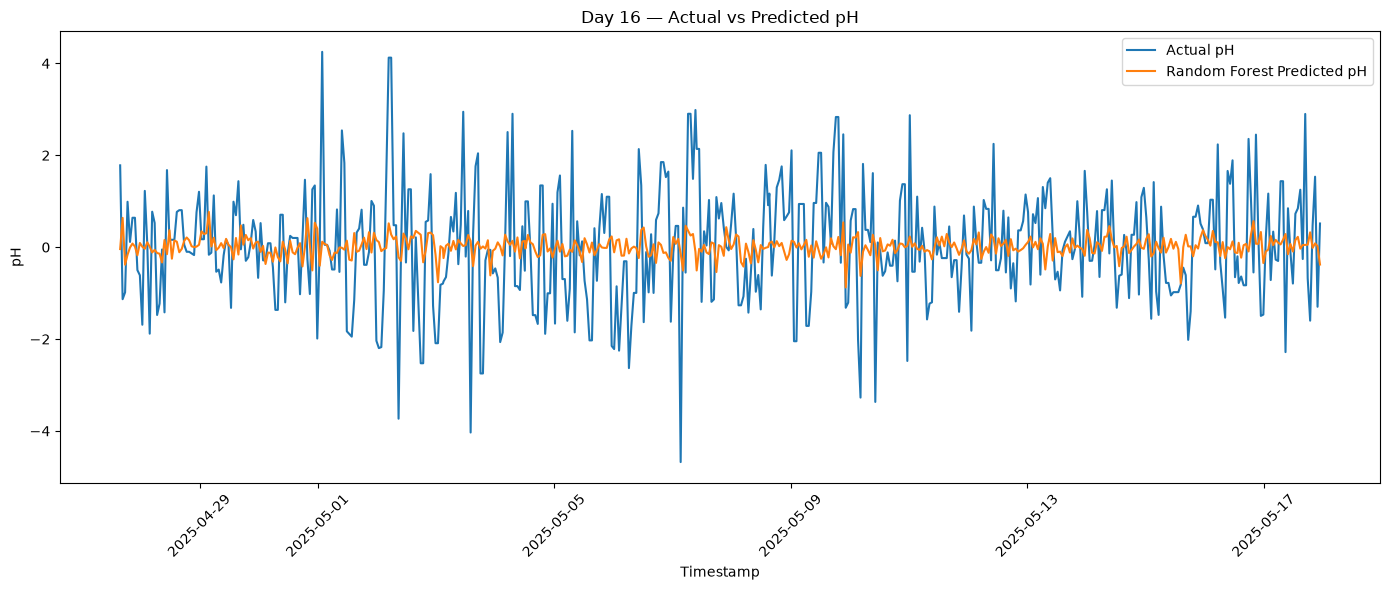

In [7]:
# Predicted vs Actual pH on chronological test data

plot_df = test_model[["timestamp", "ph_next"]].copy()

plot_df["actual"] = y_test.values
plot_df["predicted"] = test_pred

plot_df = plot_df.sort_values("timestamp")

plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["timestamp"],
    plot_df["actual"],
    label="Actual pH"
)

plt.plot(
    plot_df["timestamp"],
    plot_df["predicted"],
    label="Random Forest Predicted pH"
)

plt.title("Day 16 — Actual vs Predicted pH")
plt.xlabel("Timestamp")
plt.ylabel("pH")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

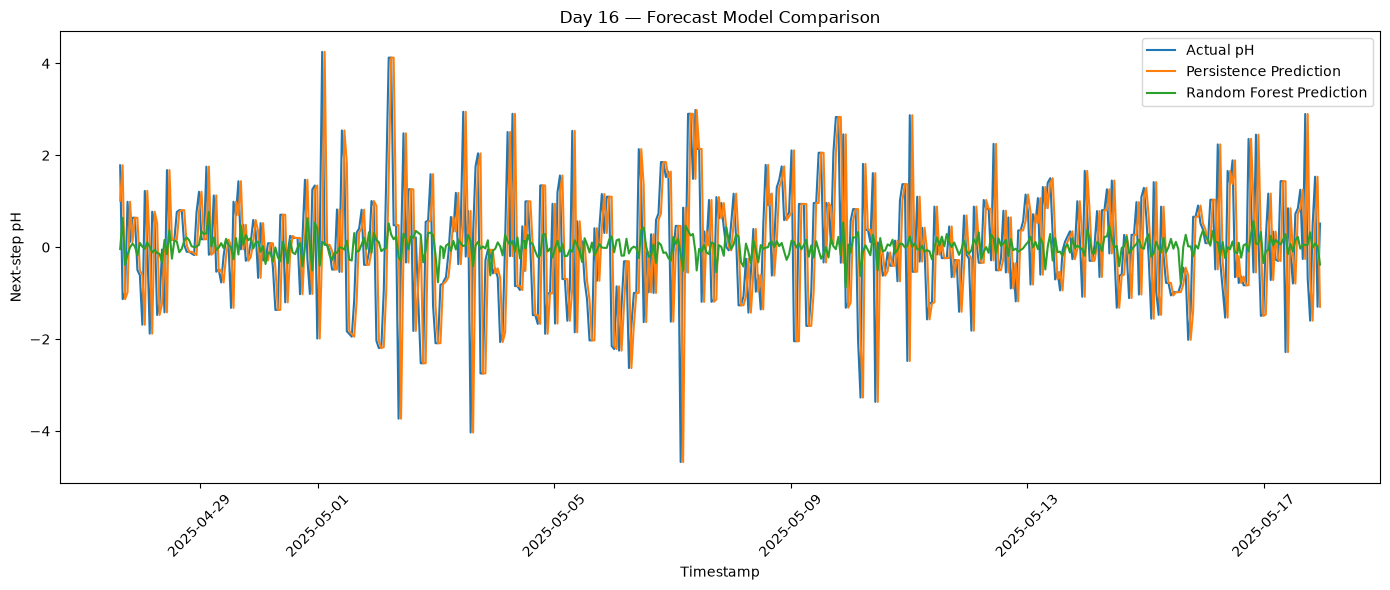

In [9]:
# Compare Persistence and Random Forest predictions

comparison_df = test_model[["timestamp"]].copy()

comparison_df["actual_next_ph"] = y_test.values
comparison_df["persistence_prediction"] = test_persistence["predicted"].values
comparison_df["random_forest_prediction"] = test_pred

comparison_df = comparison_df.sort_values("timestamp")

plt.figure(figsize=(14, 6))

plt.plot(
    comparison_df["timestamp"],
    comparison_df["actual_next_ph"],
    label="Actual pH"
)

plt.plot(
    comparison_df["timestamp"],
    comparison_df["persistence_prediction"],
    label="Persistence Prediction"
)

plt.plot(
    comparison_df["timestamp"],
    comparison_df["random_forest_prediction"],
    label="Random Forest Prediction"
)

plt.title("Day 16 — Forecast Model Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Next-step pH")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Day 16 — Final Forecasting Metrics

metrics_df = pd.DataFrame({
    "Model": [
        "Persistence",
        "Random Forest"
    ],
    "Test MAE": [
        persistence_mae,
        rf_test_mae
    ],
    "Test RMSE": [
        persistence_rmse,
        rf_test_rmse
    ]
})

metrics_df

,Model,Test MAE,Test RMSE
0,Persistence,1.133537,1.609520
1,Random Forest,0.981553,1.245266


# Day 16 — Summary and Findings

## Models Evaluated

Two next-step pH forecasting baselines were evaluated:

1. **Persistence Baseline** — predicts the next pH value using the current pH value.
2. **Random Forest Regressor** — uses current water-quality parameters, temporal features, lag features, and rolling statistics to predict the next pH value.

## Test Results

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| Persistence | 1.1335 | 1.6095 |
| Random Forest | 0.9816 | 1.2453 |

## Findings

The Random Forest model produced lower MAE and RMSE than the persistence baseline on the chronological test holdout.

This provides an initial machine-learning forecasting baseline for next-step pH prediction.

## Limitations

- The available dataset contains only water-potability-related parameters and does not include the originally requested temperature, dissolved oxygen, or pressure measurements.
- Timestamps were synthetically generated because the original dataset did not contain temporal information.
- The forecasting experiment currently focuses on pH as the target parameter.
- The current results should be treated as a baseline because the temporal structure is based on generated timestamps.

## Next Steps

Future experiments can evaluate additional forecasting models and compare their performance using the same chronological evaluation framework.